In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input/datasets/paulajibola/kmeans-data/cluster_data.csv'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import pickle
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.utils.validation import check_is_fitted

In [3]:
filename = '/kaggle/input/datasets/paulajibola/kmeans-data/cluster_data.csv'

In [4]:
df = pd.read_csv(filename)

df.head(10)

,Feature 1,Feature 2
0,2.698582,-0.672960
1,-0.128113,4.355952
2,2.509049,5.773146
3,-1.518276,3.444886
4,-0.072283,2.883769
5,9.158480,-2.022418
6,0.281702,4.154153
7,8.867313,-1.606801
8,1.690574,1.054368
9,1.575612,1.518022


In [5]:
df.describe()

,Feature 1,Feature 2
count,500.000000,500.000000
mean,1.831353,2.694970
std,4.086149,3.494165
min,-3.896491,-4.378493
25%,-1.174033,0.200712
50%,0.604212,2.807746
75%,2.750212,5.132506
max,11.867680,10.216205


In [6]:
df.info()

print(f"df shape: {df.shape}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature 1  500 non-null    float64
 1   Feature 2  500 non-null    float64
dtypes: float64(2)
memory usage: 7.9 KB
df shape: (500, 2)


In [7]:
X = df[["Feature 1", "Feature 2"]]

X.head()
print(type(X))
print(f"X shape: {X.shape}")
print(f"X info: {X.info()}")

<class 'pandas.core.frame.DataFrame'>
X shape: (500, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature 1  500 non-null    float64
 1   Feature 2  500 non-null    float64
dtypes: float64(2)
memory usage: 7.9 KB
X info: None


In [8]:
# Train the KMeans model
model = KMeans(n_clusters=3, random_state=42)

model.fit(X)

KMeans(n_clusters=3, random_state=42)

In [9]:
# check if model fits to the data
check_is_fitted(model)

print("...that went well!!")

...that went well!!


In [10]:
# exxtract the labels that were gotten during training

labels = model.labels_


print("labels type:", type(labels))
print("labels shape:", labels.shape)
labels[-10:]

labels type: <class 'numpy.ndarray'>
labels shape: (500,)


array([0, 1, 0, 0, 0, 1, 2, 0, 0, 0], dtype=int32)

In [11]:
np.unique(labels)

array([0, 1, 2], dtype=int32)

Text(0.5, 1.0, 'Feature 1 vs. Feature 2')

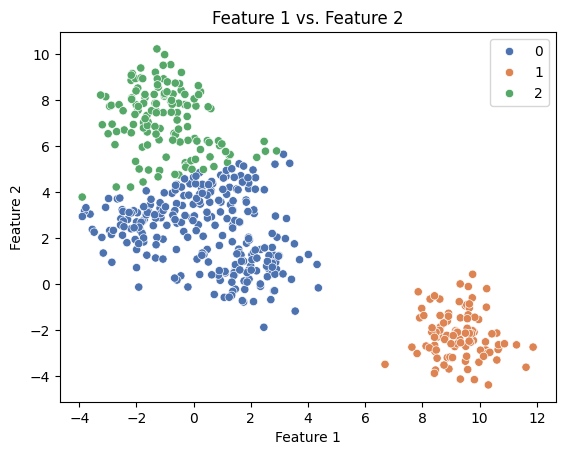

In [12]:
sns.scatterplot(x=df["Feature 1"], y=df["Feature 2"], hue=labels, palette="deep")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Feature 1 vs. Feature 2")

In [13]:
centroids = model.cluster_centers_

print(f"Print X and Y axes of centroids created during training: {centroids}")

Print X and Y axes of centroids created during training: [[ 0.44049554  2.3154064 ]
 [ 9.30286933 -2.23802673]
 [-0.97290267  7.09411175]]


Text(0.5, 1.0, 'Feature 1 vs. Feature 2')

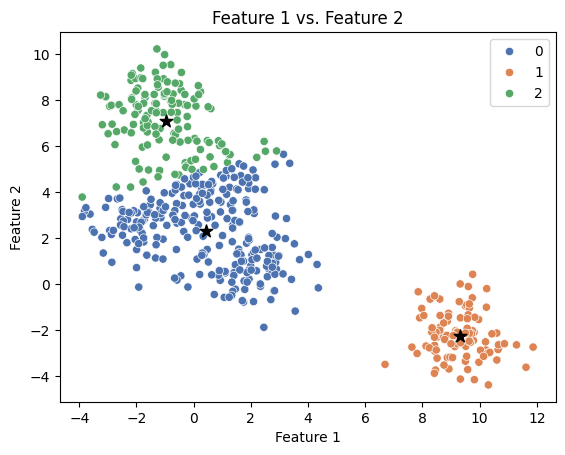

In [14]:
# plot the scatterplot and the centroids
sns.scatterplot(x=df["Feature 1"], y=df["Feature 2"], hue=labels, palette="deep")

# for centroids
plt.scatter(
    x=centroids[:, 0],
    y=centroids[:, 1],
    color="black",
    marker="*",
    # s for size
    s=90,
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Feature 1 vs. Feature 2")

In [15]:
# EVALUATE THE CLUSTERS NUMERICALLY, BEYOND THE VISUALS
# Unlike in classification (Accuracy, Precision and Recall) and Regression (Mean Abs. Error)
# In Unsupervised learning, there is no target; hence, we use:

# 1. Inertia (Within Clusters Sum of Squares) [smaller the better, best is 0]
# sum of mean of datapoints in a cluster around a centroid
inertia = model.inertia_

print("inertia type:", type(inertia))
print("Inertia (3 clusters):", inertia)

inertia type: <class 'float'>
Inertia (3 clusters): 2183.1774920196467


In [16]:
# 2. Silhouette Score
# sum of mean of datapoints around a cluster with another centroids in a different cluster
# best value = 1; it ranges from -1 (worst) to 1 (best); and it is easier to interpret.
# measures how well the model does a job of identifying how far away the clusters are from each others
ss = silhouette_score(X, model.labels_)

print("Silhouette_score (3 clusters):", ss)
print(f"Silhouette type: {type(ss)}")

Silhouette_score (3 clusters): 0.5223033306518524
Silhouette type: <class 'numpy.float64'>


In [21]:
n_clusters = range(2, 13)
inertia_errors = []
silhouette_scores = []

# Add `for` loop to train model and calculate inertia, silhouette score.
for k in n_clusters:
    # Build the model
    model = KMeans(n_clusters=k, random_state=42)
    # Train the model
    model.fit(X)
    # Calculate inertia
    inertia_errors.append(model.inertia_)
    # Calculate the ss
    silhouette_scores.append(silhouette_score(X, model.labels_))

print("inertia_errors type:", type(inertia_errors))
print("inertia_errors len:", len(inertia_errors))
print("Inertia:", inertia_errors)
print()
print("silhouette_scores type:", type(silhouette_scores))
print("silhouette_scores len:", len(silhouette_scores))
print("Silhouette Scores:", silhouette_scores)

inertia_errors type: <class 'list'>
inertia_errors len: 11
Inertia: [4390.702977889531, 2183.1774920196467, 1351.7375876504561, 880.2717191277227, 799.3400427257601, 727.4229755132577, 661.6018200359144, 601.2967047805056, 524.3275855546826, 488.28859713279144, 447.1401560485521]

silhouette_scores type: <class 'list'>
silhouette_scores len: 11
Silhouette Scores: [np.float64(0.6669572967784785), np.float64(0.5223033306518524), np.float64(0.5227130808451921), np.float64(0.5590512042420652), np.float64(0.510862953541574), np.float64(0.46596014376178296), np.float64(0.36696022183509386), np.float64(0.3481016368389471), np.float64(0.3552801517031706), np.float64(0.3439718946510831), np.float64(0.3523056206314666)]


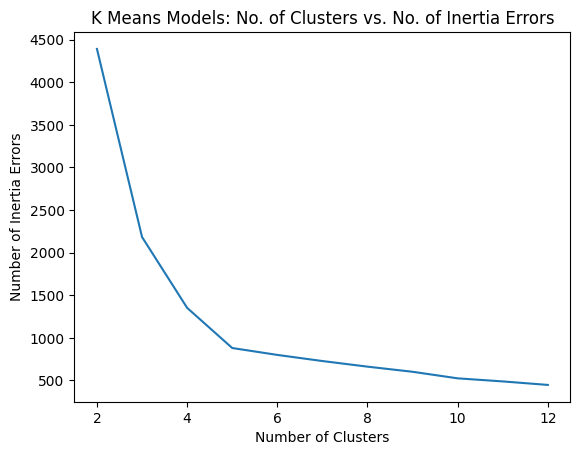

In [30]:
# plot the inertia against the n_clusters
# This is an elbow plot and what you are looking for is the bend in the elbow. This point is the
# point of diminishing return. That is the best number of clusters

# it appears to be 4 and 5 here.

plt.plot(n_clusters, inertia_errors)
plt.xlabel(("Number of Clusters"))
plt.ylabel("Number of Inertia Errors")
plt.title("K Means Models: No. of Clusters vs. No. of Inertia Errors");

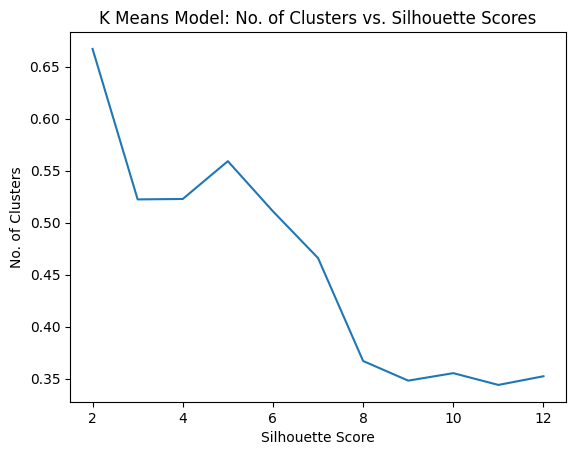

In [32]:
plt.plot(n_clusters, silhouette_scores)

plt.xlabel("Silhouette Score")
plt.ylabel("No. of Clusters")
plt.title("K Means Model: No. of Clusters vs. Silhouette Scores");

# comparing 4 and 5 from above to decide on the better inertia value to take. 5 looks better
# in this case. Remember, in this case, the closer to 1, the better.

In [34]:
# using the better score: 5, we recreate the model

final_model = KMeans(n_clusters=5, random_state=42)


final_model.fit(X)

KMeans(n_clusters=5, random_state=42)

In [51]:
final_model.labels_

array([4, 0, 0, 3, 0, 1, 0, 1, 4, 4, 2, 3, 0, 2, 3, 1, 3, 1, 0, 3, 4, 1,
       4, 0, 4, 2, 4, 4, 2, 3, 4, 0, 0, 2, 0, 4, 4, 1, 1, 1, 2, 1, 3, 4,
       0, 4, 1, 0, 4, 2, 0, 1, 4, 4, 1, 0, 1, 1, 2, 3, 4, 1, 4, 0, 0, 2,
       0, 2, 0, 0, 0, 4, 3, 1, 0, 0, 4, 4, 3, 4, 3, 2, 0, 0, 1, 4, 1, 0,
       0, 3, 3, 2, 2, 3, 1, 4, 4, 3, 2, 0, 4, 0, 2, 4, 0, 0, 1, 4, 4, 0,
       0, 3, 4, 1, 1, 2, 2, 2, 4, 1, 1, 2, 0, 2, 3, 0, 1, 3, 2, 2, 0, 4,
       0, 1, 2, 1, 1, 1, 0, 3, 4, 2, 4, 3, 4, 1, 1, 2, 3, 0, 0, 2, 2, 4,
       0, 0, 0, 0, 2, 3, 2, 1, 3, 0, 4, 4, 3, 4, 1, 4, 3, 0, 1, 1, 4, 2,
       3, 2, 0, 2, 0, 2, 2, 1, 3, 1, 4, 0, 2, 1, 2, 4, 1, 0, 4, 3, 0, 1,
       2, 2, 4, 2, 0, 2, 2, 4, 1, 3, 3, 0, 1, 2, 0, 2, 1, 2, 1, 4, 4, 0,
       4, 3, 1, 1, 1, 0, 3, 1, 1, 3, 4, 3, 0, 2, 2, 0, 2, 3, 1, 0, 4, 0,
       2, 1, 4, 4, 2, 2, 4, 1, 1, 0, 4, 4, 0, 0, 3, 0, 3, 2, 1, 3, 2, 4,
       0, 3, 1, 4, 3, 0, 0, 2, 3, 4, 2, 4, 2, 4, 2, 2, 3, 4, 4, 4, 0, 4,
       2, 3, 2, 1, 3, 0, 0, 0, 4, 1, 2, 3, 1, 2, 1,

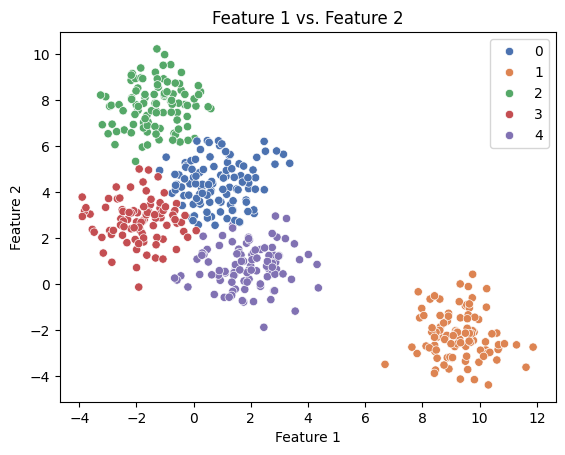

In [38]:
# communicate the final model
sns.scatterplot(
    x=df["Feature 1"],
    y=df["Feature 2"],
    hue=final_model.labels_,
    palette="deep"
)


plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Feature 1 vs. Feature 2");

In [47]:
print("X head:", X.head(10))
print("X info:", X.info())
print("X shape:", X.shape)

X head:    Feature 1  Feature 2
0   2.698582  -0.672960
1  -0.128113   4.355952
2   2.509049   5.773146
3  -1.518276   3.444886
4  -0.072283   2.883769
5   9.158480  -2.022418
6   0.281702   4.154153
7   8.867313  -1.606801
8   1.690574   1.054368
9   1.575612   1.518022
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature 1  500 non-null    float64
 1   Feature 2  500 non-null    float64
dtypes: float64(2)
memory usage: 7.9 KB
X info: None
X shape: (500, 2)


In [41]:
mean_by_group = X.groupby(final_model.labels_).mean()

print("mean_by_group type:", type(mean_by_group))
print("mean_by_group shape:", mean_by_group.shape)

mean_by_group

mean_by_group type: <class 'pandas.core.frame.DataFrame'>
mean_by_group shape: (5, 2)


,Feature 1,Feature 2
0,0.824910,4.373960
1,9.302869,-2.238027
2,-1.336255,7.738230
3,-1.877070,2.748058
4,1.875450,0.763376


In [46]:
final_model.cluster_centers_

# notice that the cluster_centers_ are approximately the same values as the mean of each
# group of the data

array([[ 0.82491004,  4.37395978],
       [ 9.30286933, -2.23802673],
       [-1.33625465,  7.73822965],
       [-1.87707045,  2.74805822],
       [ 1.87544954,  0.76337636]])

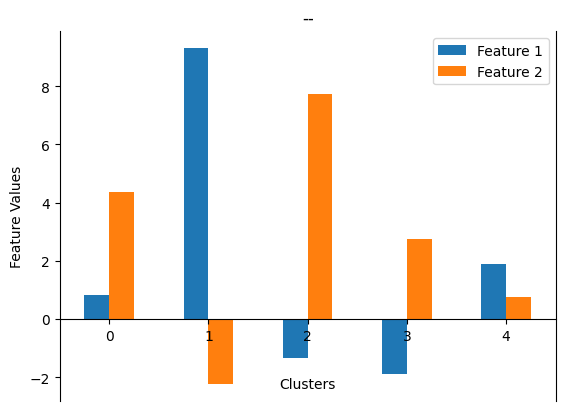

In [65]:
mean_by_group.plot(kind="bar")


ax = plt.gca()  # 'gca': grab current axis
ax.spines['bottom'].set_position('zero')
ax.spines['top'].set_visible(False)


plt.xlabel("Clusters", labelpad=25)
plt.ylabel("Feature Values")
plt.title("--");